# Future of Labor: the second-order story and the long view — the code behind the numbers

Companion notebook for the HON 4013 guest slides (board "Future of Labor: the second-order story and the long view").
It reproduces every number and graph on those slides that comes from a calculation: the textile arithmetic, the
"one country freezes" growth gap, and all of the population charts.

**What you need:** an internet connection (about 50 MB of UN data is downloaded once) and `pyreadr`, installed below.
It runs in under a minute on a CPU; no GPU is used.

**Where the numbers come from:** the population figures are the United Nations' *World Population Prospects 2024*,
read from the `wpp2024` data package (github.com/PPgp/wpp2024): estimates for 1950–2023 and the medium-variant
projection for 2024–2100. A few slide numbers come from published sources rather than code; they are listed at the end.

In [1]:
%pip install -q pyreadr

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd
import pyreadr

# The wpp2024 data files, pinned to the commit the slides were made from
WPP_COMMIT = "2da7768ae64fc74105d3f9e98f9a74d37b62f99a"
WPP_URL = f"https://github.com/PPgp/wpp2024/raw/{WPP_COMMIT}/data/"
DATA_DIR = "wpp2024_data"

# UN country codes for every country on the slides
CODES = {392: "Japan", 410: "South Korea", 380: "Italy", 156: "China", 826: "United Kingdom",
         840: "United States", 356: "India", 566: "Nigeria", 348: "Hungary", 100: "Bulgaria",
         642: "Romania", 300: "Greece", 276: "Germany", 900: "World"}

# One colour and one marker per country, the same as on the slides
STYLE = {"United States": ("#2557D6", "s"), "Japan": ("#C2510F", "o"), "United Kingdom": ("#16181D", "^"),
         "India": ("#16181D", "^"), "South Korea": ("#7B3FC4", "D"), "China": ("#7B3FC4", "D"),
         "Italy": ("#0B7A5E", "x"), "Nigeria": ("#0B7A5E", "x"), "World": ("#6B7080", "")}

In [3]:
def load_wpp(name):
    """Download one wpp2024 data file (once) and return it as a DataFrame."""
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, f"{name}.rda")
    if not os.path.exists(path):
        urllib.request.urlretrieve(WPP_URL + f"{name}.rda", path)
    return pyreadr.read_r(path)[name]


# Population by single year of age, in thousands: estimates 1949-2023, projections 2024-2100
pop_age = load_wpp("popAge1dt")
pop_age = pop_age[pop_age.country_code.isin(CODES) & (pop_age.year >= 1950)]
proj_age = load_wpp("popprojAge1dt")
proj_age = proj_age[proj_age.country_code.isin(CODES)].copy()
proj_age["pop"] = proj_age["popM"] + proj_age["popF"]          # medium variant
for frame in (pop_age, proj_age):                               # some files store year and age as text
    frame["year"] = frame["year"].astype(int)
    frame["age"] = frame["age"].astype(int)

# Total population per year (estimates) and the medium-variant projected totals
pop_total = pop_age.groupby(["country_code", "year"])["pop"].sum()
proj_total = load_wpp("popproj1dt")
proj_total = proj_total[proj_total.country_code.isin(CODES)].set_index(["country_code", "year"])
proj_total = proj_total["popM"] + proj_total["popF"]

# Births per woman (total fertility rate), estimates 1950-2023
tfr = load_wpp("tfr1dt")
tfr = tfr[tfr.country_code.isin(CODES)].set_index(["country_code", "year"])["tfr"]

CODE_OF = {name: code for code, name in CODES.items()}
print("loaded", len(pop_age), "age rows,", len(proj_age), "projected age rows")

loaded 104636 age rows, 108878 projected age rows


In [4]:
def total_population(name):
    """Total population (thousands) by year, 1950-2100: estimates to 2023, then the projection."""
    code = CODE_OF[name]
    series = pop_total.loc[code].copy()
    series = pd.concat([series, proj_total.loc[code]])
    return series.sort_index()


def plot_country(ax, name, years, values, split_year, marker_every=25):
    """Draw one country: solid up to split_year, dashed after, a marker every few years, one legend entry."""
    color, marker = STYLE[name]
    years = list(years)
    values = list(values)
    past = [(y, v) for y, v in zip(years, values) if y <= split_year]
    future = [(y, v) for y, v in zip(years, values) if y >= split_year]
    width = 2 if name == "World" else 2.5
    ax.plot([y for y, _ in past], [v for _, v in past], color=color, lw=width)
    if len(future) > 1:
        ax.plot([y for y, _ in future], [v for _, v in future], color=color, lw=width, ls="--")
    marked = [(y, v) for y, v in zip(years, values) if y % marker_every == 0 and marker]
    ax.plot([y for y, _ in marked], [v for _, v in marked], ls="none", marker=marker, color=color, markersize=6)
    ax.plot([], [], color=color, lw=width, marker=marker or None, label=name)   # one legend entry: line and marker

## Cheap cloth, and What if one country froze automation?

*Both slides are hidden in the presented deck; the arithmetic is kept here for reference.*

Two numbers on these slides are plain arithmetic on published figures. Yarn prices are Clark's (shillings per pound,
1784 and 1832); the hand weaver's pay per 28-yard piece (3s 0d in 1815, 1s 4d in 1830) is the table published by
Spartacus Educational. The growth gap asks how much richer neighbours become if they grow 1 (or 2) percentage points
a year faster for 30 years.

In [5]:
yarn_1784, yarn_1832 = 11.0, 1.0                      # shillings per pound of cotton yarn
pence_1815, pence_1830 = 3 * 12 + 0, 1 * 12 + 4       # 3s 0d and 1s 4d, in pence

print(f"Yarn cost change, 1784-1832: {(yarn_1832 - yarn_1784) / yarn_1784:.1%}")          # slide: -91%
print(f"Hand weaver's pay per piece, 1815-1830: {(pence_1830 - pence_1815) / pence_1815:.1%}")  # 'more than half'
for extra_growth in (0.01, 0.02):
    print(f"{extra_growth:.0%} faster growth for 30 years -> neighbours {(1 + extra_growth) ** 30:.3f}x as rich")

Yarn cost change, 1784-1832: -90.9%
Hand weaver's pay per piece, 1815-1830: -55.6%
1% faster growth for 30 years -> neighbours 1.348x as rich
2% faster growth for 30 years -> neighbours 1.811x as rich


## Declining Birth Rates

Observed data only. Left: births per woman since 1950, against the replacement level of 2.1. The year a country fell
below 2.1 *for good* is the first year after which it never came back above. Right: countries whose population has
already passed its peak, shown as their 2023 population as a share of that peak.

United Kingdom  births per woman 2023: 1.56; below 2.1 since 1973
United States   births per woman 2023: 1.62; below 2.1 since 1972
Japan           births per woman 2023: 1.21; below 2.1 since 1974
Italy           births per woman 2023: 1.20; below 2.1 since 1976
South Korea     births per woman 2023: 0.72; below 2.1 since 1984
Bulgaria   peak 1988, 2023 = 75% of peak
Romania    peak 1990, 2023 = 83% of peak
Hungary    peak 1979, 2023 = 91% of peak
Greece     peak 2010, 2023 = 91% of peak
Japan      peak 2009, 2023 = 97% of peak
Italy      peak 2013, 2023 = 98% of peak


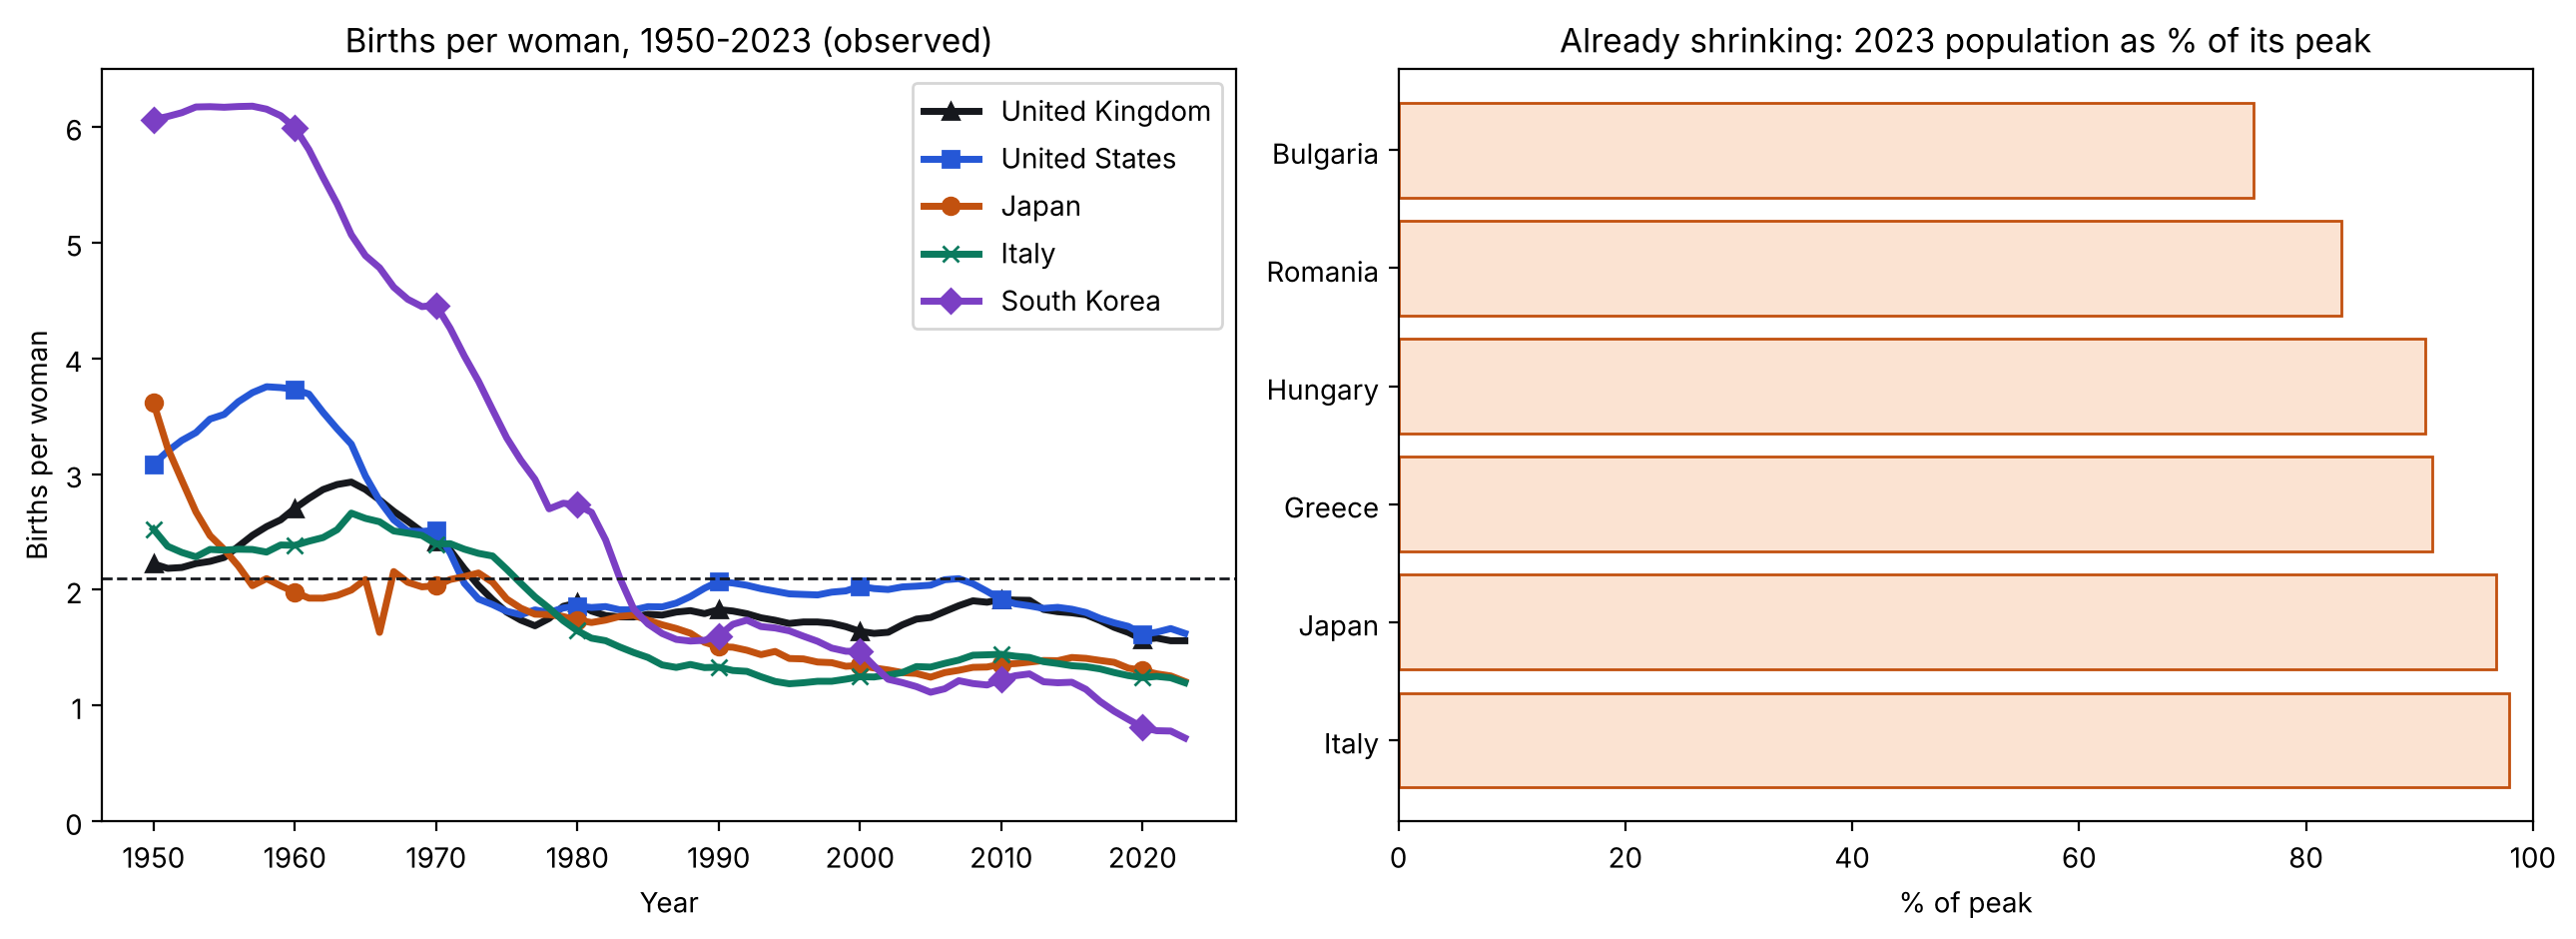

In [6]:
LEFT = ["United Kingdom", "United States", "Japan", "Italy", "South Korea"]
SHRINKING = ["Bulgaria", "Romania", "Hungary", "Greece", "Japan", "Italy"]


def below_replacement_since(series):
    """First year from which births per woman stayed below 2.1 through 2023."""
    years = sorted(series.index)
    for year in years:
        if all(series[y] < 2.1 for y in years if y >= year):
            return year
    return None


fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 4.8))
for name in LEFT:
    births = tfr.loc[CODE_OF[name]]
    plot_country(ax_left, name, births.index, births.values, split_year=2023, marker_every=10)
    print(f"{name:15s} births per woman 2023: {births[2023]:.2f}; below 2.1 since {below_replacement_since(births)}")
ax_left.axhline(2.1, color="#16181D", ls="--", lw=1)
ax_left.set(title="Births per woman, 1950-2023 (observed)", xlabel="Year", ylabel="Births per woman", ylim=(0, 6.5))
ax_left.legend()

shares = []
for name in SHRINKING:
    people = pop_total.loc[CODE_OF[name]]
    peak_year = int(people.idxmax())
    share = 100 * people[2023] / people.max()
    shares.append(share)
    print(f"{name:10s} peak {peak_year}, 2023 = {share:.0f}% of peak")
ax_right.barh(SHRINKING[::-1], shares[::-1], color="#FBE3D2", edgecolor="#C2510F")
ax_right.set(title="Already shrinking: 2023 population as % of its peak", xlabel="% of peak", xlim=(0, 100))
plt.tight_layout()
plt.show()

## Not the future: already here

The working-age population (everyone aged 18 to 64), as a share of each country's own peak. The year of that peak is
when a country's pool of potential workers started shrinking. The closing slide's peak years come from this cell too.

Japan           18-64 peaked 1996; 2023 = 84% of peak; 2050 = 62%
Germany         18-64 peaked 1996; 2023 = 96% of peak; 2050 = 79%
Italy           18-64 peaked 2010; 2023 = 96% of peak; 2050 = 68%
China           18-64 peaked 2014; 2023 = 98% of peak; 2050 = 75%
South Korea     18-64 peaked 2018; 2023 = 97% of peak; 2050 = 63%
United Kingdom  18-64 peaked 2044; 2023 = 95% of peak; 2050 = 99%
India           18-64 peaked 2048; 2023 = 85% of peak; 2050 = 100%
Nigeria         18-64 peaked 2097; 2023 = 37% of peak; 2050 = 70%


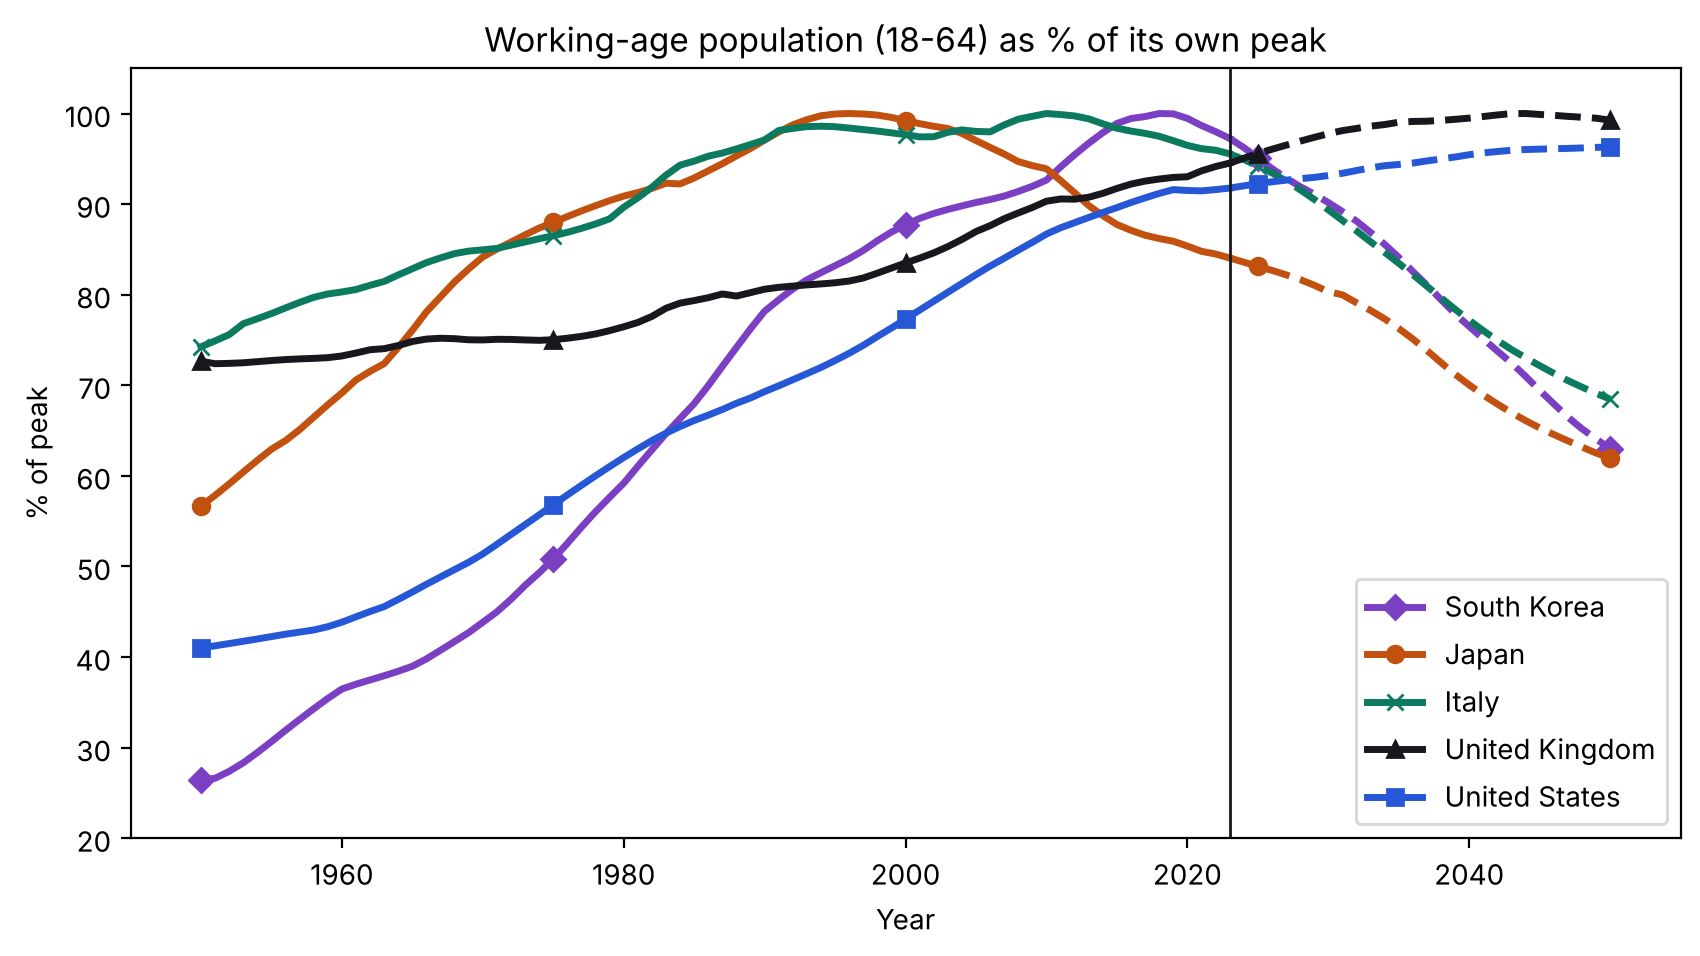

In [7]:
WORKING = ["South Korea", "Japan", "Italy", "United Kingdom", "United States"]
PEAK_LIST = ["Japan", "Germany", "Italy", "China", "South Korea", "United Kingdom", "India", "Nigeria"]


def working_age_population(name):
    """Population aged 18-64 (thousands) by year, 1950-2100."""
    code = CODE_OF[name]
    frames = []
    for frame in (pop_age, proj_age):
        rows = frame[(frame.country_code == code) & (frame.age >= 18) & (frame.age <= 64)]
        frames.append(rows.groupby("year")["pop"].sum())
    return pd.concat(frames).sort_index()


for name in PEAK_LIST:
    workers = working_age_population(name)
    peak_year = int(workers.idxmax())
    print(f"{name:15s} 18-64 peaked {peak_year}; 2023 = {100 * workers[2023] / workers.max():.0f}% of peak; "
          f"2050 = {100 * workers[2050] / workers.max():.0f}%")

fig, ax = plt.subplots(figsize=(10, 5))
for name in WORKING:
    workers = working_age_population(name)
    share = 100 * workers / workers.max()
    share = share[(share.index >= 1950) & (share.index <= 2050)]
    plot_country(ax, name, share.index, share.values, split_year=2023)
ax.axvline(2023, color="#16181D", lw=1)
ax.set(title="Working-age population (18-64) as % of its own peak", xlabel="Year", ylabel="% of peak", ylim=(20, 105))
ax.legend()
plt.show()

## How many people? 1950 to 2100

Each country's population divided by its own 2025 population, so countries of very different sizes share one axis.
Solid lines are estimates; dashed lines (after 2025) are the UN medium projection. The slide plots every fifth year.

Nigeria        1950:    16   2100:   199   peak year 2100
United States  1950:    45   2100:   121   peak year 2100
India          1950:    24   2100:   102   peak year 2061
Japan          1950:    71   2100:    62   peak year 2009
China          1950:    39   2100:    44   peak year 2020


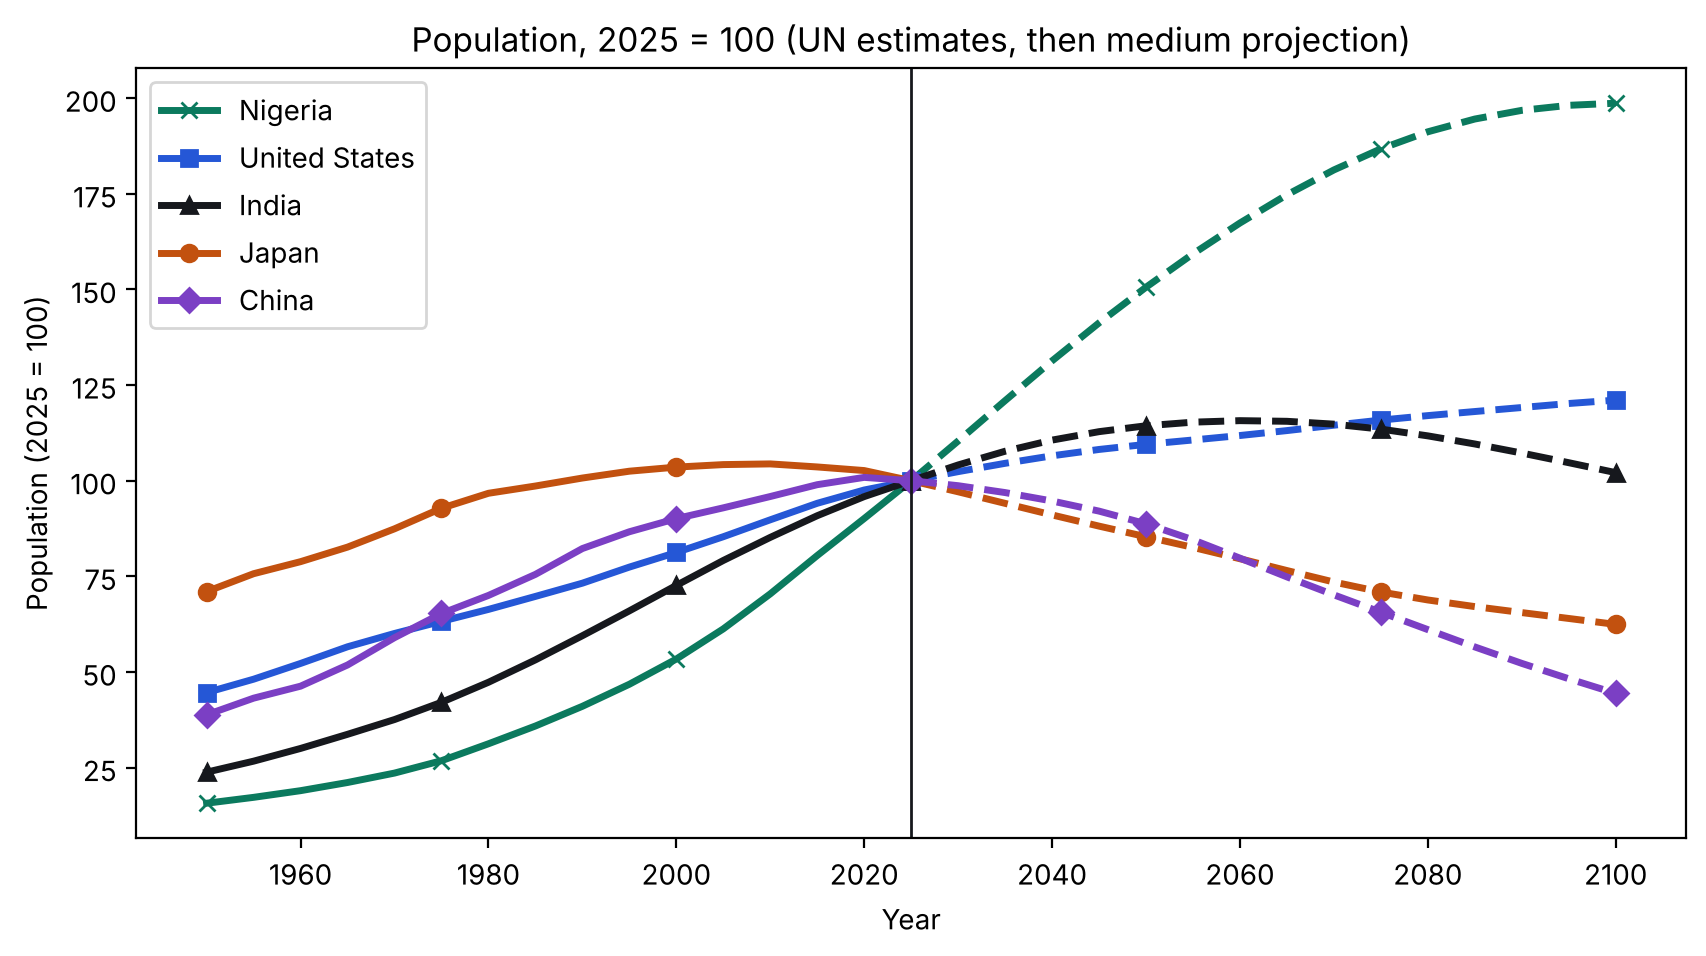

In [8]:
FIVE = ["Nigeria", "United States", "India", "Japan", "China"]

fig, ax = plt.subplots(figsize=(10, 5))
for name in FIVE:
    people = total_population(name)
    index = 100 * people / people[2025]
    every_five = index[index.index % 5 == 0]
    plot_country(ax, name, every_five.index, every_five.values, split_year=2025)
    print(f"{name:14s} 1950: {index[1950]:5.0f}   2100: {index[2100]:5.0f}   peak year {int(people.idxmax())}")
ax.axvline(2025, color="#16181D", lw=1)
ax.set(title="Population, 2025 = 100 (UN estimates, then medium projection)", xlabel="Year", ylabel="Population (2025 = 100)")
ax.legend()
plt.show()

## Who is over 65?

Two charts on one timeline. Top: population with 2025 = 100. Bottom: the share of **adults** (everyone aged 18 and
over) who are 65 or older. The slower the top line grows, the faster the bottom one climbs.

Nigeria        adults 65+: 1950    6%  2000    6%  2023    6%  2050    7%  2100   16%
United States  adults 65+: 1950   12%  2000   16%  2023   23%  2050   29%  2100   34%


World          adults 65+: 1950    9%  2000   11%  2023   14%  2050   22%  2100   30%
Japan          adults 65+: 1950    8%  2000   22%  2023   35%  2050   43%  2100   44%
South Korea    adults 65+: 1950    5%  2000   10%  2023   22%  2050   44%  2100   51%


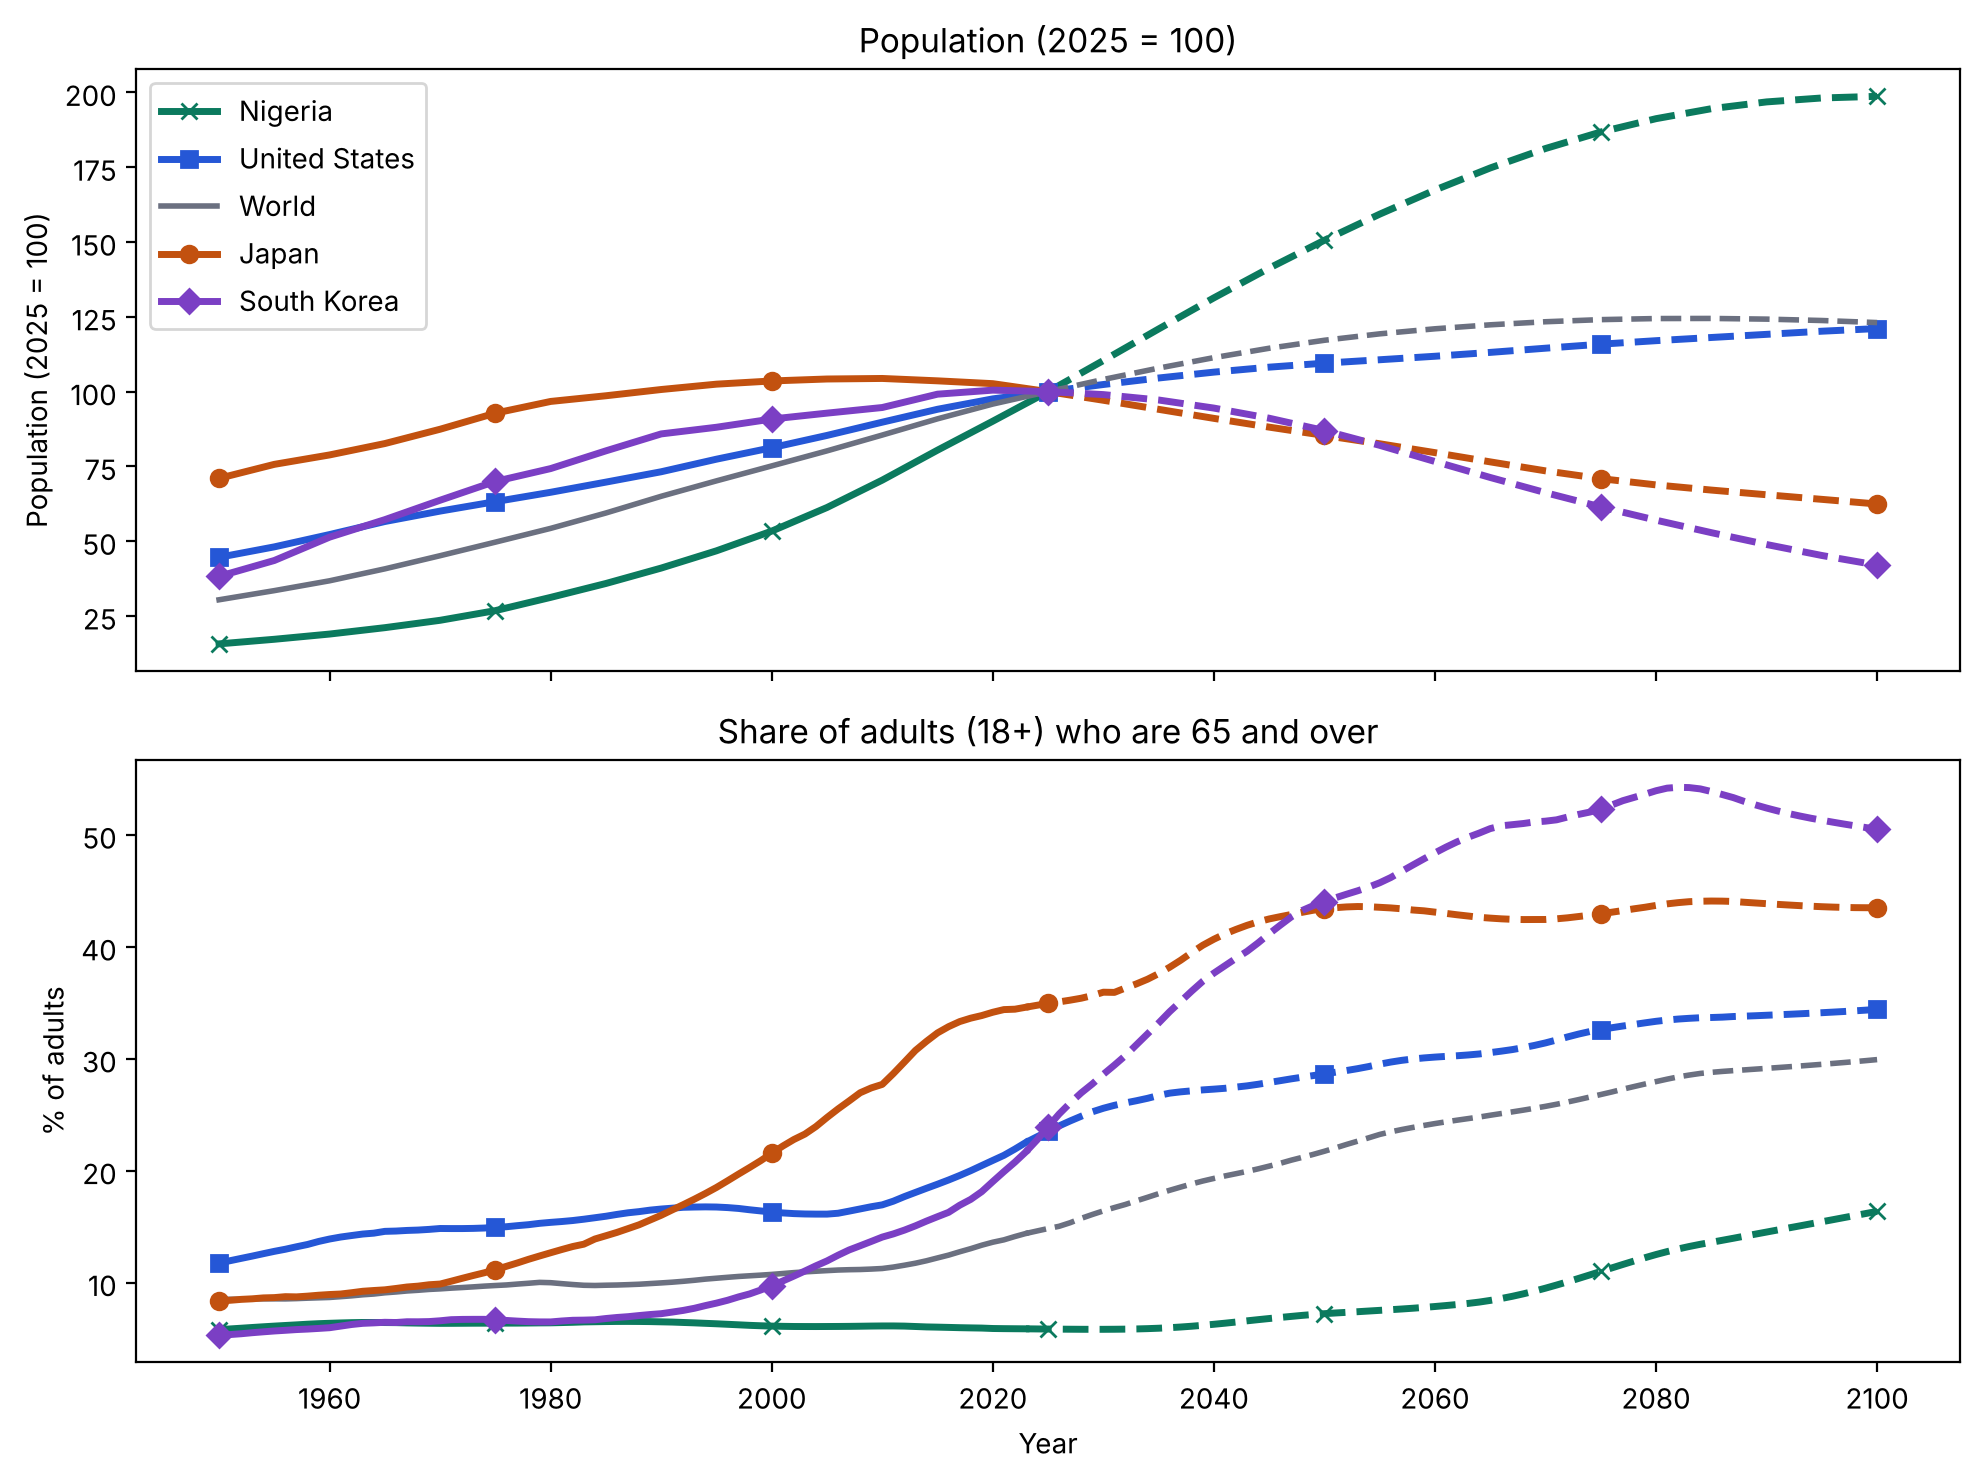

In [9]:
STACK = ["Nigeria", "United States", "World", "Japan", "South Korea"]


def share_of_adults_over_65(name):
    """Percent of adults (18+) aged 65+, per year, 1950-2100."""
    code = CODE_OF[name]
    frames = [pop_age[pop_age.country_code == code], proj_age[proj_age.country_code == code]]
    ages = pd.concat([f[["year", "age", "pop"]] for f in frames])
    adults = ages[ages.age >= 18].groupby("year")["pop"].sum()
    over_65 = ages[ages.age >= 65].groupby("year")["pop"].sum()
    return 100 * over_65 / adults


fig, (ax_pop, ax_old) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
for name in STACK:
    people = total_population(name)
    index = 100 * people / people[2025]
    every_five = index[index.index % 5 == 0]
    plot_country(ax_pop, name, every_five.index, every_five.values, split_year=2025)
    old = share_of_adults_over_65(name)
    plot_country(ax_old, name, old.index, old.values, split_year=2023)
    print(f"{name:14s} adults 65+: 1950 {old[1950]:4.0f}%  2000 {old[2000]:4.0f}%  2023 {old[2023]:4.0f}%  "
          f"2050 {old[2050]:4.0f}%  2100 {old[2100]:4.0f}%")
ax_pop.set(title="Population (2025 = 100)", ylabel="Population (2025 = 100)")
ax_old.set(title="Share of adults (18+) who are 65 and over", xlabel="Year", ylabel="% of adults")
ax_pop.legend()
plt.tight_layout()
plt.show()

## When would people have to retire?

Suppose a country wants to keep **1 in 6 adults retired**. For each year, find the age at which the people that age
and older make up exactly 1/6 of everyone aged 18 and over. Within a single year of age, people are assumed to be
spread evenly, so the answer can fall between whole years. The dashed line on the slide marks 65.

South Korea    1975  53.9   2023  68.2   2050  80.8   2100  88.2
Japan          1975  59.8   2023  76.7   2050  80.9   2100  85.6
United States  1975  63.5   2023  69.0   2050  74.3   2100  79.0
World          1975  58.1   2023  62.9   2050  69.0   2100  75.3
Nigeria        1975  53.9   2023  52.4   2050  54.4   2100  64.8


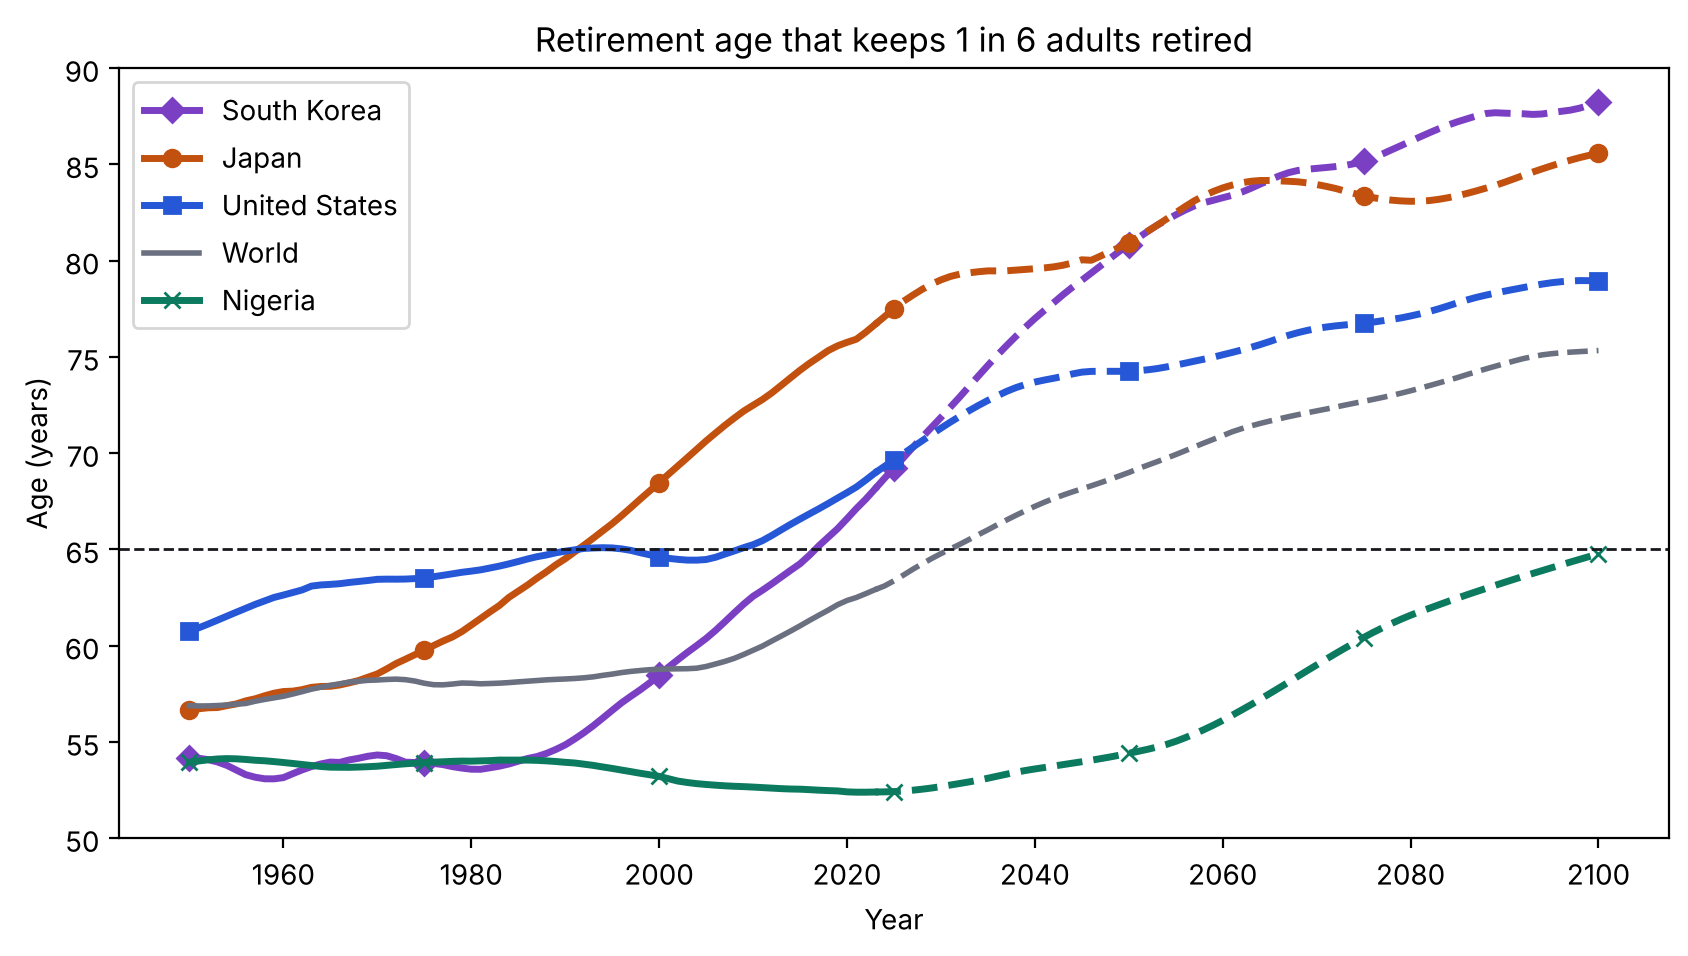

In [10]:
SHARE_RETIRED = 1 / 6
RETIRE = ["South Korea", "Japan", "United States", "World", "Nigeria"]


def retirement_age(ages, people, share=SHARE_RETIRED):
    """Age A at which everyone aged A and over is `share` of the adults (18+)."""
    adults = sum(p for a, p in zip(ages, people) if a >= 18)
    target = share * adults
    older = 0.0                                   # people older than the current single year of age
    for age, count in sorted(zip(ages, people), reverse=True):
        if older + count >= target:
            return age + 1 - (target - older) / count
        older += count
    return 18.0


fig, ax = plt.subplots(figsize=(10, 5))
for name in RETIRE:
    code = CODE_OF[name]
    rows = pd.concat([pop_age[pop_age.country_code == code][["year", "age", "pop"]],
                      proj_age[proj_age.country_code == code][["year", "age", "pop"]]])
    ages_by_year = {year: retirement_age(g.age.tolist(), g["pop"].tolist()) for year, g in rows.groupby("year")}
    curve = pd.Series(ages_by_year).sort_index()
    plot_country(ax, name, curve.index, curve.values, split_year=2023)
    print(f"{name:14s} 1975 {curve[1975]:5.1f}   2023 {curve[2023]:5.1f}   2050 {curve[2050]:5.1f}   2100 {curve[2100]:5.1f}")
ax.axhline(65, color="#16181D", ls="--", lw=1)
ax.set(title="Retirement age that keeps 1 in 6 adults retired", xlabel="Year", ylabel="Age (years)", ylim=(50, 90))
ax.legend()
plt.show()

## Numbers on the slides that do not come from code

These are quoted from their sources, not computed here.

- **The other side of the ledger / Same shortage, different answers:** South Korea's births per woman in 2025 (0.80)
  is from Statistics Korea (February 2026); the UN data above end in 2023 (0.72).
- **The other side of the ledger:** South Korea's projected old-age dependency ratio (31.3 in 2026, 68.4 in 2045,
  103.3 in 2070) is Statistics Korea's projection as reported by the Korea Times (November 2026). The slide's other
  numbers (peak around 2084, more than half of countries below replacement, more over-65s than under-18s by 2080)
  are from the UN's *World Population Prospects 2024* summary. (In the data above the world total peaks in 2083; the UN's
  report says 2084.)
- **Same shortage, different answers:** robot density (industrial robots per 10,000 manufacturing workers) is from the
  International Federation of Robotics, *World Robotics 2025*; Japan's foreign workers from its Ministry of Health,
  Labour and Welfare (January 2026); Africa's job needs from Lam, Leibbrandt and Allen.
- **Does automation help when workers run short?:** the finding that ageing explains close to half of the cross-country
  differences in robot adoption is from Acemoglu and Restrepo, *Review of Economic Studies* (2022). The care card
  ("as a helper") and the Japan row on *Same shortage, different answers* rest on Eggleston, Iizuka, Lee and Xi
  (Stanford, 2026): Japanese nursing homes that adopted care robots (monitoring, lifting and transfer aids) employed
  more care workers, about 28% more, and kept staff longer. A survey reported by RIETI (2025) finds about three-quarters
  of care facilities now use monitoring, mobility or transfer robots; an older 2019 survey that counted only dedicated
  care robots found about 10%.
- **Who pays for the retirees?:** Norway's Government Pension Fund Global was worth about NOK 21,300 billion at the end
  of 2025, about NOK 3.8 million per registered resident (Norwegian Ministry of Finance). Japan's primary income, its
  earnings from overseas investments, was ¥42.28 trillion in fiscal 2025 (Ministry of Finance).
- **Why Britain first?:** the table ranks wages and energy prices qualitatively (no numbers), following Robert Allen,
  *The British Industrial Revolution in Global Perspective* (2009). The link from the Black Death to high wages and later
  marriage is from Voigtländer and Voth, *American Economic Review* (2013).
- **Cheap cloth / Every machine moved the bottleneck:** British export share and the enslaved population of the US are
  historical figures from the sources listed on those slides.